# PCA: sustitución parcial de k puntos por QR directo

Diez semillas, 100 pasos uniformes y 10000 de continuación. Se mantiene PCA centrada + media al 95%, candidatos fijos, 20 snapshots cada 5 pasos del último intervalo de 100 y 128 activos. Red, Adam y pérdida histórica datos+PDE+IC coinciden con el notebook 19.

**Referencia:** reconstruir con k pivotes QR y 128−k Sobol, reutilizada del notebook 19. **PCA parcial:** conservar 128−k activos y proponer k puntos por QR sobre la base restringida a candidatos que no están activos. PCA se ajusta sobre la historia completa. **Sobol parcial:** misma regla de poda y el mismo k de la trayectoria PCA parcial en cada semilla e intervalo; no usa un rango propio para decidir la cantidad. Este control está emparejado y depende de la corrida PCA, no es un método autónomo de rango.

Los tres brazos comparten la primera selección y el primer intervalo. La primera poda ocurre en paso 200. Se retiran los k puntos con mayor log2(|r anterior|/|r actual|), con piso 1e-12. Si alguno tiene grado negativo se cancela toda la sustitución. Se recompone la referencia de residuo sobre las coordenadas actualizadas. Los candidatos propuestos son disjuntos de los activos; esto requiere restringir QR a los elegibles. Después de la primera actualización las historias divergen con cada entrenamiento. No se renuevan candidatos ni se amplía con log-det.

| Método | RMSE prueba ± DE | Residuo RMS | RMSE IC |
|---|---:|---:|---:|
| PCA: poda de k | 0.09870 ± 0.02202 | 0.08080 | 0.12944 |
| Sobol: poda de k emparejado | 0.05674 ± 0.04708 | 1.23932 | 0.02650 |
| PCA: reconstrucción | 0.07144 ± 0.00977 | 0.16801 | 0.08991 |


PCA: poda de k frente a PCA: reconstrucción: diferencia media RMSE +0.02726; mejora en 0/10 semillas.

PCA: poda de k frente a Sobol: poda de k emparejado: diferencia media RMSE +0.04196; mejora en 1/10 semillas.

**Comparación**

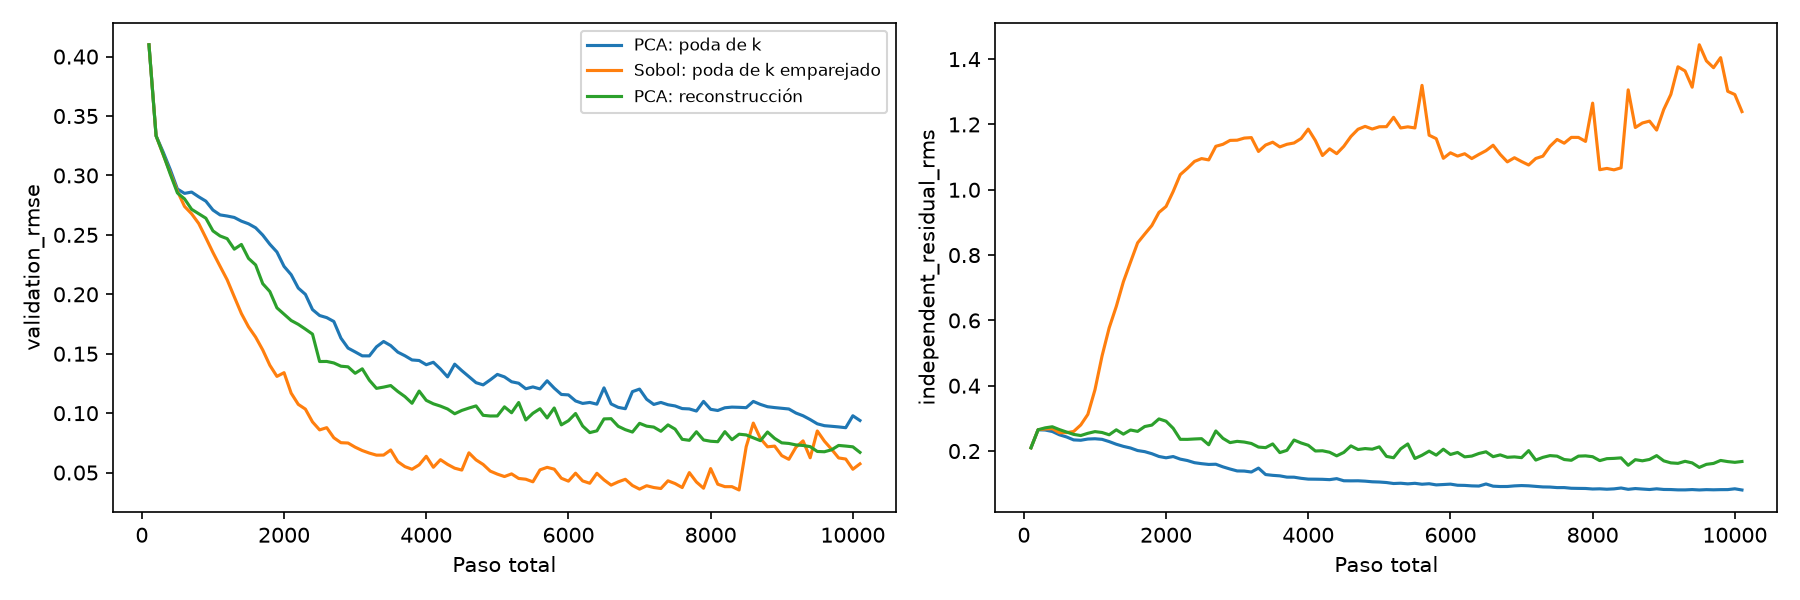

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/rank_pruning/pca95_rank_pruning_10_seeds_10k_v1/comparison.png'), format='png', embed=True))


PCA: poda de k: 990/990 sustituciones aceptadas. k entre 2 y 10, media 6.01.

Sobol: poda de k emparejado: 990/990 sustituciones aceptadas. k entre 2 y 10, media 6.01.

Se evalúa el modelo terminal en tiempos de prueba reservados, sin elegir por prueba. Las dispersiones son entre semillas. residence.csv registra permanencias: los sobrevivientes finales son observaciones censuradas y no deben mezclarse sin distinción con permanencias completas. rank_pruning.csv guarda propuestas, aceptación y cantidad efectiva. Se reconstruyeron 80 podas guardadas y se comprobó inicio común y calendario k emparejado. Los tiempos incluyen cálculo y diagnóstico y no prueban aceleración.

Reproducir: `python scripts/run_collocation_rank_pruning.py`. Las corridas completas se reutilizan. Las figuras están incrustadas como PNG. El siguiente cambio a considerar es renovar candidatos, condicionado a los resultados de este control.